# ACA N° 2 – Aprendizaje Automático
## Del ML clásico al Deep Learning: clasificación de ecografías mamarias con redes neuronales y despliegue en Streamlit

**Corporación Unificada Nacional de Educación Superior (CUN)** · Escuela de Ingeniería · Especialización en Inteligencia Artificial
**Asignatura:** Aprendizaje Automático · **Docente:** Hamilton Rivera Flor
**Integrantes:**
- Kevin David Guzman Payares
- Leider Antonio Pacheco Quinto
- Joaquin Pablo Redondo Tapias
- Jose Luis Ruiz Ospino

**Pilar:** Salud · **Dataset:** Breast Ultrasound Images (BUSI) – Al-Dhabyani et al. (2020) · **Puente con ACA 1:** UCI Breast Cancer Wisconsin (Diagnostic)

---
### Contenido
1. Situación problema, objetivos y dataset
2. Configuración del entorno
3. **PASO 1** – Exploración y gestión SQL (SQLite)
4. **PASO 2** – Preparación y pipeline (depuración, partición, aumento de datos)
5. **PASO 3** – Modelado neuronal (CNN desde cero, EfficientNet-B0, Vision Transformer de Hugging Face)
6. **PASO 4** – Evaluación y métricas (curvas, matriz de confusión, ROC, IC 95 %, Grad-CAM)
7. Puente con el ACA 1: MLP vs. regresión logística en WDBC
8. Exportación de artefactos para la app (**PASO 5**)
9. Conclusiones, limitaciones y referencias

## 1. Situación problema, objetivos y dataset

**Pregunta orientadora.** ¿Cómo aprovechar las arquitecturas de redes neuronales (CNN, RNN, Transformers) o modelos de Hugging Face para extraer patrones complejos en datos de salud, optimizando el rendimiento predictivo y permitiendo su interacción práctica a través de una interfaz en Streamlit?

**Situación problema.** En el ACA 1 clasificamos masas mamarias como benignas o malignas a partir de **30 medidas ya extraídas** de imágenes de citología (WDBC); la regresión logística alcanzó ROC-AUC = 0,996. Sin embargo, en la práctica clínica el primer examen suele ser una **ecografía**, y alguien debe interpretar la imagen. Aquí damos el paso siguiente: que la red neuronal **aprenda directamente de la imagen** de ultrasonido y distinga tejido **normal**, lesión **benigna** y lesión **maligna**.

**Objetivo general.** Entrenar y ajustar redes neuronales profundas (CNN y Transformer) que clasifiquen ecografías mamarias en tres clases, priorizando la sensibilidad para la clase maligna, y desplegarlas en una aplicación Streamlit que muestre la predicción y la región de la imagen que la justifica (Grad-CAM).

**Objetivos específicos.**
1. Gestionar el inventario de imágenes y las predicciones en una base de datos **SQLite**.
2. Depurar el dataset (duplicados y etiquetas contradictorias) y construir una partición **sin fuga de información**.
3. Comparar tres arquitecturas: CNN desde cero, **EfficientNet-B0** con *transfer learning* y **DeiT-Small** (Vision Transformer de Hugging Face).
4. Evaluar con loss, accuracy, F1, matriz de confusión, ROC y bootstrap; interpretar con Grad-CAM.

**Dataset.** *Breast Ultrasound Images Dataset* (BUSI), Hospital Baheya (El Cairo), 2018: 780 imágenes PNG de 600 mujeres de 25 a 75 años, en tres carpetas (`normal`, `benign`, `malignant`), cada una con su máscara de segmentación de la lesión (licencia CC BY 4.0).

## 2. Configuración del entorno

*Local o Google Colab:* el notebook espera la carpeta `utils/` junto a él. Si el dataset no está en `data/raw/`, la celda siguiente lo descarga (204 MB) desde la copia pública de Hugging Face.

In [1]:
import json, os, shutil, sqlite3, time, warnings, zipfile, urllib.request
from pathlib import Path

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image
from torch.utils.data import DataLoader

from utils.config import (BASE, CLASES, COLORES, DIR_EJEMPLOS, DIR_FIGURAS, DIR_MODELOS, DIR_RAW, IMG_SIZE,
                          RUTA_DB, SEED)
from utils import db
from utils.datos import (BusiDataset, depurar, escanear_busi, particionar, transformaciones, cargar_imagen)
from utils.modelos import (CNNSimple, ViTClasificador, congelar_efficientnet, contar_parametros, crear_efficientnet)
from utils.entrenamiento import bootstrap_ic, entrenar, fijar_semillas, metricas, predecir
from utils.gradcam import GradCAM, capa_objetivo, energia_en_mascara, superponer

fijar_semillas(SEED)
torch.set_num_threads(os.cpu_count())
for d in (DIR_FIGURAS, DIR_MODELOS, DIR_EJEMPLOS):
    d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False})
PALETA = [COLORES[c] for c in CLASES]

def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / nombre, dpi=150)
    plt.show()

# Descarga del dataset si no existe (copia pública de BUSI en Hugging Face, CC BY 4.0)
if not DIR_RAW.exists():
    url = ("https://huggingface.co/datasets/gymprathap/Breast-Cancer-Ultrasound-Images-Dataset/resolve/main/"
           "Breast-Cancer-Ultrasound-Images-Dataset.zip")
    zip_path = DIR_RAW.parent / "busi.zip"
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(url, zip_path)
    zipfile.ZipFile(zip_path).extractall(DIR_RAW.parent)

print(f"PyTorch {torch.__version__} · hilos CPU: {torch.get_num_threads()} · GPU: {torch.cuda.is_available()}")
print("Dataset en:", DIR_RAW.relative_to(BASE))

PyTorch 2.15.0+cpu · hilos CPU: 12 · GPU: False
Dataset en: data\raw\Dataset_BUSI_with_GT


## 3. PASO 1 – Exploración y gestión de datos con SQL

### 3.1 Inventario de imágenes → SQLite
Recorremos las carpetas, descartamos las máscaras (`*_mask.png`) como entrada del modelo y, por cada ecografía, calculamos: tamaño, intensidad media, número de máscaras, **fracción de la imagen ocupada por la lesión** (a partir de la máscara), huella **MD5** y **hash perceptual (pHash)** para detectar duplicados. Todo se almacena en la tabla `imagenes` de `data/busi.db`.

In [2]:
t0 = time.time()
inv = escanear_busi()
print(f"{len(inv)} imágenes inventariadas en {time.time() - t0:.0f} s")

con = db.conectar()
print("Filas insertadas en SQLite:", db.cargar_imagenes(con, inv))
print(db.consultar(con, "SELECT name, sql FROM sqlite_master WHERE type='table'").to_string()[:900])

780 imágenes inventariadas en 15 s
Filas insertadas en SQLite: 780
              name                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  


In [3]:
# Consultas SQL de exploración
q_clases = db.consultar(con, '''
    SELECT clase, COUNT(*) AS n, ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM imagenes),1) AS pct,
           ROUND(AVG(ancho)) AS ancho_medio, ROUND(AVG(alto)) AS alto_medio,
           ROUND(AVG(intensidad_media),1) AS intensidad, ROUND(100*AVG(area_lesion),1) AS pct_area_lesion,
           SUM(n_mascaras > 1) AS con_varias_lesiones
    FROM imagenes GROUP BY clase ORDER BY n DESC''')
display(q_clases)
display(db.consultar(con, '''
    SELECT md5, GROUP_CONCAT(archivo, '  |  ') AS archivos, COUNT(*) AS n
    FROM imagenes GROUP BY md5 HAVING n > 1'''))

,clase,n,pct,ancho_medio,alto_medio,intensidad,pct_area_lesion,con_varias_lesiones
0,benigno,437,56.0,613.0,495.0,86.3,6.9,16
1,maligno,210,26.9,598.0,494.0,79.8,14.7,1
2,normal,133,17.1,651.0,533.0,81.0,0.0,0


,md5,archivos,n
0,88f5ac307c1827b335d8b981c31262dc,benign/benign (433).png | malignant/malignan...,2


**Lectura.** El dataset está **desbalanceado**: 56 % benignas, 27 % malignas y 17 % normales. Las imágenes tienen tamaños distintos (~500×600 px), por lo que habrá que redimensionarlas. Las lesiones malignas ocupan en promedio más área que las benignas, y algunas imágenes contienen más de una lesión. La consulta por MD5 ya revela un archivo **idéntico guardado en dos clases distintas**: es la primera señal de que hace falta depurar.

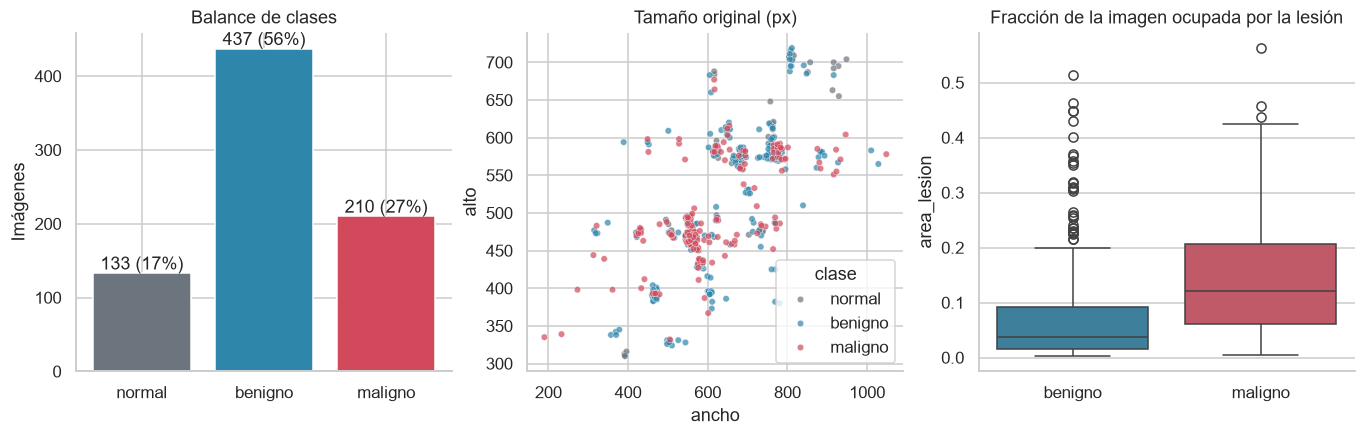

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cnt = inv["clase"].value_counts().reindex(CLASES)
axes[0].bar(CLASES, cnt.values, color=PALETA)
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + 5, f"{v} ({v / len(inv):.0%})", ha="center")
axes[0].set_title("Balance de clases"); axes[0].set_ylabel("Imágenes")
sns.scatterplot(data=inv, x="ancho", y="alto", hue="clase", hue_order=CLASES, palette=PALETA, ax=axes[1], s=18, alpha=.7)
axes[1].set_title("Tamaño original (px)")
sns.boxplot(data=inv[inv.clase != "normal"], x="clase", y="area_lesion", order=["benigno", "maligno"],
            palette=PALETA[1:], ax=axes[2])
axes[2].set_title("Fracción de la imagen ocupada por la lesión"); axes[2].set_xlabel("")
guardar(fig, "01_eda_clases_tamanos.png")

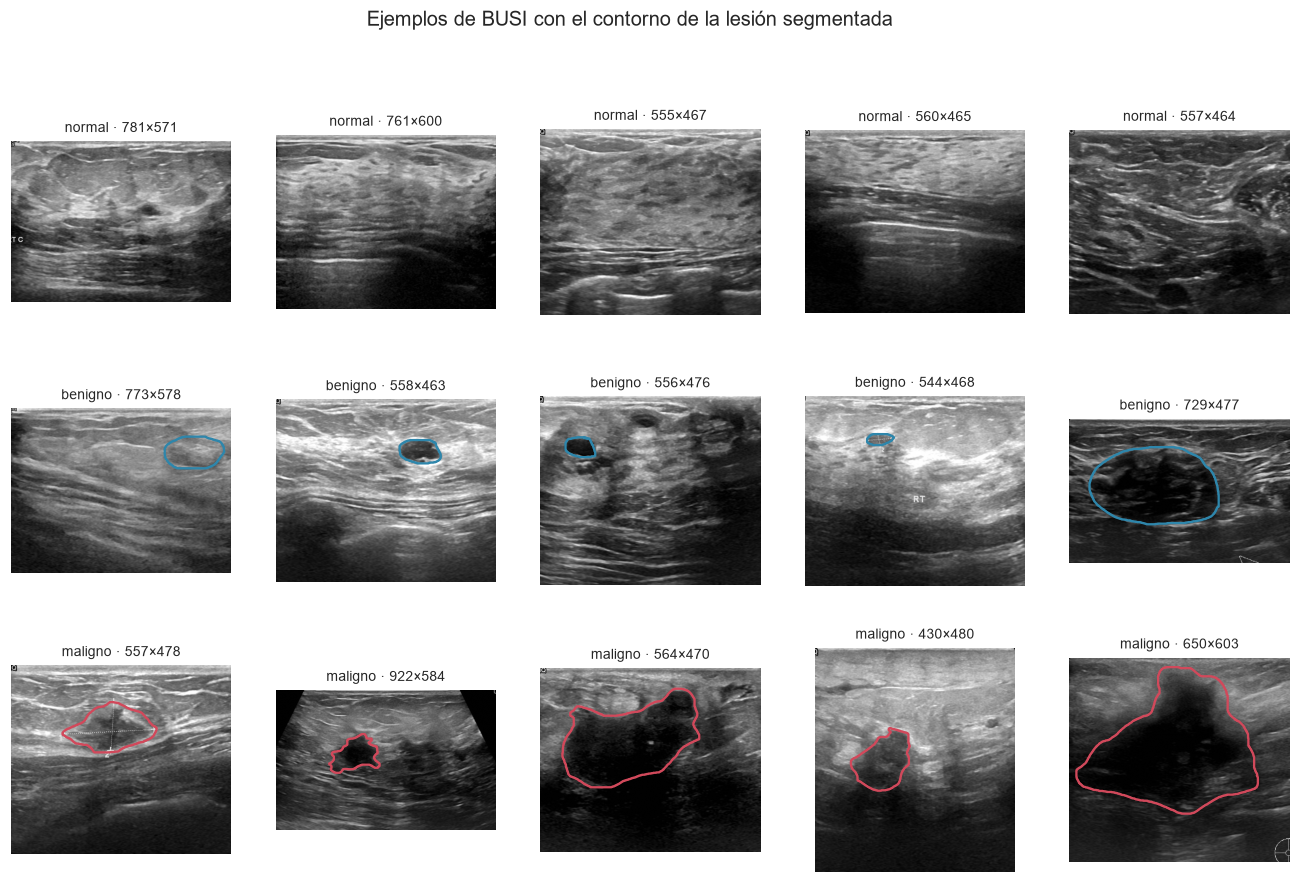

In [5]:
# Mosaico: ecografía + contorno de la lesión (máscara) por clase
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
rng = np.random.default_rng(SEED)
for f, clase in enumerate(CLASES):
    sub = inv[inv.clase == clase].sample(5, random_state=SEED)
    for c, (_, r) in enumerate(sub.iterrows()):
        ruta = DIR_RAW / r.archivo
        img = np.asarray(Image.open(ruta).convert("L"))
        axes[f, c].imshow(img, cmap="gray")
        for m in ruta.parent.glob(f"{ruta.stem}_mask*.png"):
            mk = np.asarray(Image.open(m).convert("L").resize(img.shape[::-1]))
            if mk.max() > 0:
                axes[f, c].contour(mk > 127, colors=[COLORES[clase]], linewidths=1.5)
        axes[f, c].set_title(f"{clase} · {r.ancho}×{r.alto}", fontsize=9); axes[f, c].axis("off")
fig.suptitle("Ejemplos de BUSI con el contorno de la lesión segmentada", fontsize=13)
guardar(fig, "02_mosaico_clases.png")

Las lesiones **benignas** tienden a ser ovaladas, de bordes definidos; las **malignas**, irregulares, con bordes espiculados y sombra acústica posterior. Las imágenes **normales** no tienen lesión (máscara vacía). Algunas incluyen texto o marcas del ecógrafo, que la red podría aprender como "atajo"; lo vigilaremos con Grad-CAM.

## 4. PASO 2 – Preparación y pipeline

### 4.1 Depuración: duplicados y etiquetas contradictorias
BUSI tiene problemas de calidad documentados: la misma ecografía aparece varias veces (a veces recortada o re-exportada) y, en algunos casos, **en clases diferentes**. Comparamos todas las parejas de imágenes por la distancia de Hamming de su pHash (0 = visualmente idénticas):

| Regla | Distancia pHash | Acción |
|---|---|---|
| Misma imagen en dos clases distintas | ≤ 4 | **Excluir** todas (etiqueta no confiable) |
| Imagen repetida dentro de la misma clase | 0 | Conservar sólo una |
| Imágenes muy parecidas (mismo paciente, cortes contiguos) | ≤ 10 | Mismo `grupo_dup` → **siempre en la misma partición** |

motivo   conflicto de etiqueta  duplicado visual  conservada
clase                                                       
benigno                     10                27         400
maligno                      6                 2         202
normal                       2                 9         122

Imágenes conservadas: 724 · grupos de casi-duplicados con >1 imagen: 117 (tamaño máx. 7)


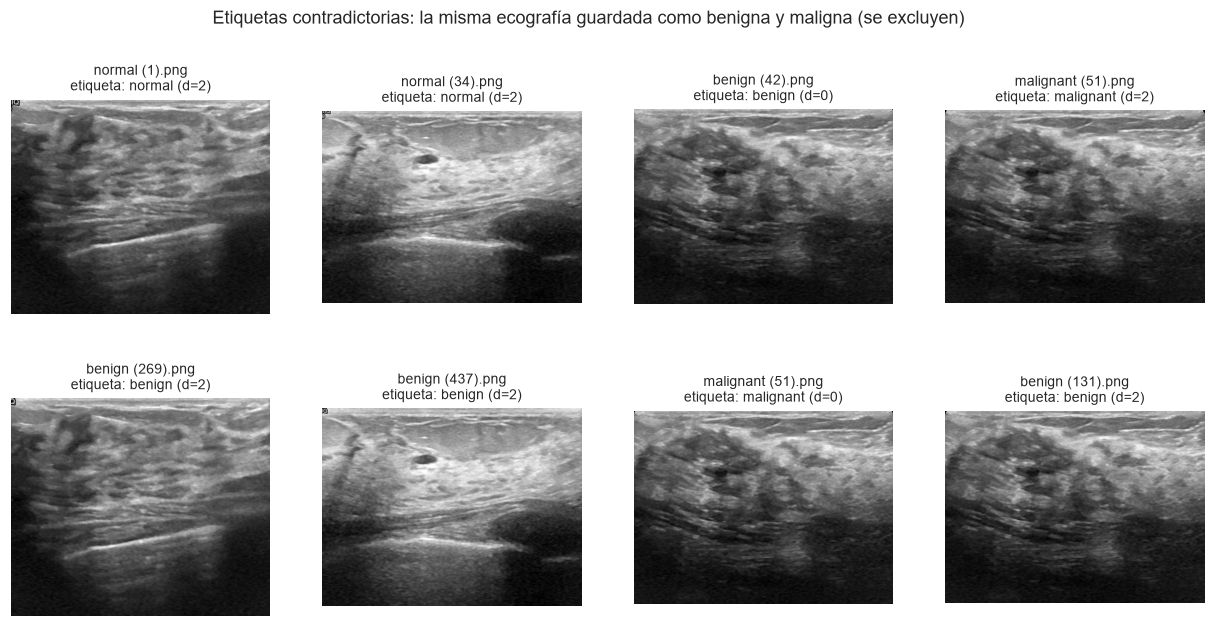

In [6]:
dep = depurar(inv)
print(dep.groupby(["clase", "motivo"], dropna=False).size().unstack(fill_value=0).rename(columns={np.nan: "conservada"}))
tam = dep[dep.excluida == 0].groupby("grupo_dup").size()
print(f"\nImágenes conservadas: {(dep.excluida == 0).sum()} · grupos de casi-duplicados con >1 imagen: {(tam > 1).sum()} "
      f"(tamaño máx. {tam.max()})")

# Ejemplos de etiquetas contradictorias
conf = dep[dep.motivo == "conflicto de etiqueta"].sort_values("phash")
import imagehash
H = {r.archivo: imagehash.hex_to_hash(r.phash) for r in conf.itertuples()}
pares = []
for i, a in enumerate(conf.archivo):
    for b in conf.archivo[i + 1:]:
        if H[a] - H[b] <= 4 and dep.set_index("archivo").clase[a] != dep.set_index("archivo").clase[b]:
            pares.append((a, b, H[a] - H[b]))
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for k, (a, b, d) in enumerate(pares[:4]):
    for f, arch in enumerate((a, b)):
        axes[f, k].imshow(Image.open(DIR_RAW / arch).convert("L"), cmap="gray"); axes[f, k].axis("off")
        axes[f, k].set_title(f"{arch.split('/')[1]}\netiqueta: {arch.split('/')[0]} (d={d})", fontsize=9)
fig.suptitle("Etiquetas contradictorias: la misma ecografía guardada como benigna y maligna (se excluyen)", fontsize=12)
guardar(fig, "03_depuracion_conflictos.png")

### 4.2 Partición estratificada y agrupada (sin fuga)
Usamos `StratifiedGroupKFold` (20 pliegues): 3 pliegues para **prueba**, 3 para **validación** y el resto para **entrenamiento** (≈ 70/15/15), conservando la proporción de clases y sin separar imágenes de un mismo grupo. La partición se **escribe en SQLite** para que sea reproducible y auditable.

In [7]:
ok = dep[dep.excluida == 0].copy()
ok["particion"] = particionar(ok)
dep["particion"] = ok["particion"]
db.cargar_imagenes(con, dep)

display(db.consultar(con, '''
    SELECT clase,
           SUM(particion='train') AS train, SUM(particion='val') AS val, SUM(particion='test') AS test,
           SUM(excluida) AS excluidas
    FROM imagenes GROUP BY clase ORDER BY clase'''))
fuga = db.consultar(con, '''SELECT grupo_dup FROM imagenes WHERE excluida=0
                            GROUP BY grupo_dup HAVING COUNT(DISTINCT particion) > 1''')
print("Grupos de casi-duplicados repartidos en más de una partición (debe ser 0):", len(fuga))

df_train, df_val, df_test = (db.consultar(con, "SELECT * FROM imagenes WHERE particion=? ORDER BY id", (p,))
                             for p in ("train", "val", "test"))
print(f"train={len(df_train)} · val={len(df_val)} · test={len(df_test)}")

,clase,train,val,test,excluidas
0,benigno,280,60,60,37
1,maligno,141,30,31,8
2,normal,86,18,18,11


Grupos de casi-duplicados repartidos en más de una partición (debe ser 0): 0
train=507 · val=108 · test=109


### 4.3 Pipeline de imágenes y aumento de datos
- Cada ecografía (escala de grises) se replica a **3 canales** y se redimensiona a 256×256; las redes preentrenadas en ImageNet esperan 3 canales y la **normalización de ImageNet**.
- **Entrenamiento:** recorte aleatorio (75–100 % del área) a 224×224, volteo horizontal, rotación ±15° y variación de brillo/contraste ±20 %. Simulan cambios reales de posición del transductor y de ganancia del ecógrafo, sin alterar la anatomía (no usamos volteo vertical: la piel siempre está arriba).
- **Validación/prueba:** sólo redimensionar a 224×224 y normalizar.
- **Desbalance:** pérdida de entropía cruzada **ponderada** por la inversa de la frecuencia de cada clase.
- **Generación de datos con IA (GAN/difusión):** se descartó a propósito; con 500 imágenes de entrenamiento, una imagen sintética mal generada podría introducir patrones falsos en un contexto clínico.

Imágenes cargadas en memoria en 11 s
Frecuencias train: {'normal': 86, 'benigno': 280, 'maligno': 141} → pesos de la pérdida: {'normal': 1.9700000286102295, 'benigno': 0.6000000238418579, 'maligno': 1.2000000476837158}
Lote: (32, 3, 224, 224) torch.float32 · rango -2.12 2.64


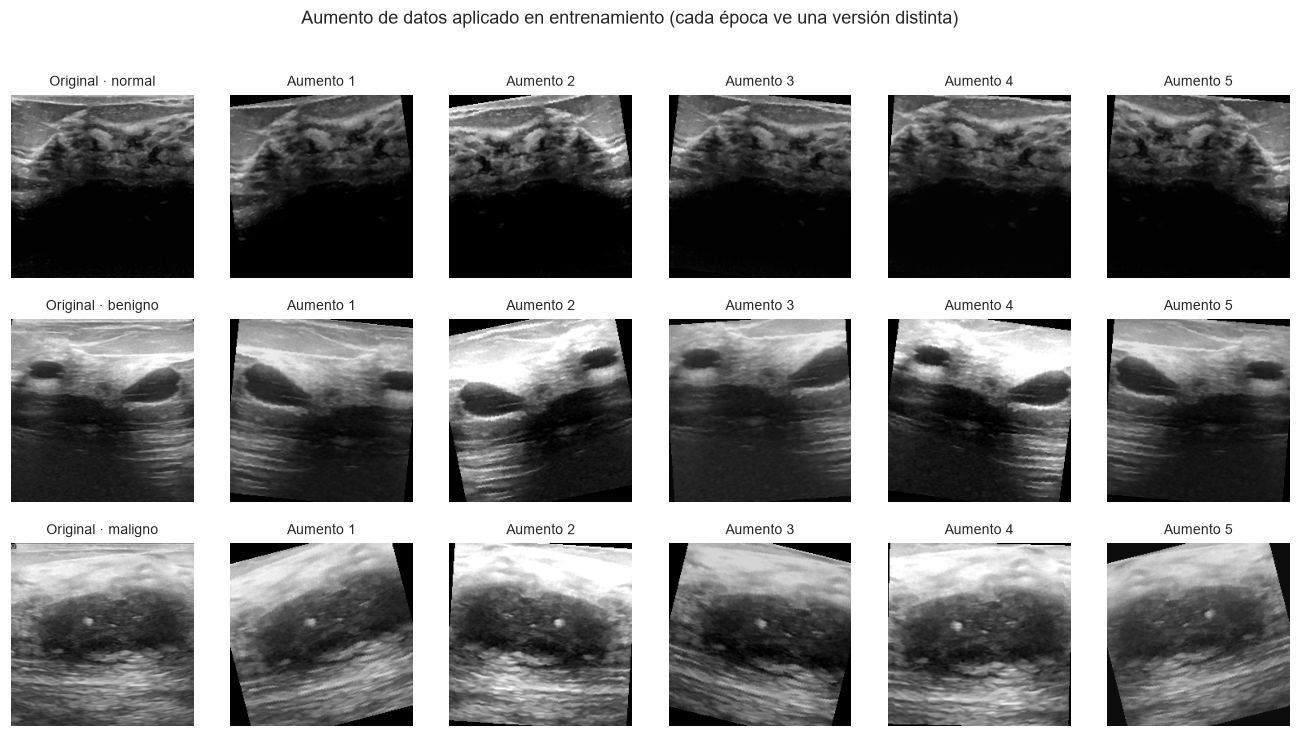

In [8]:
t0 = time.time()
ds_train = BusiDataset(df_train, transform=transformaciones(True))
ds_val = BusiDataset(df_val, transform=transformaciones(False))
ds_test = BusiDataset(df_test, transform=transformaciones(False))
print(f"Imágenes cargadas en memoria en {time.time() - t0:.0f} s")

g = torch.Generator().manual_seed(SEED)
dl_train = DataLoader(ds_train, batch_size=32, shuffle=True, generator=g)
dl_val = DataLoader(ds_val, batch_size=64)
dl_test = DataLoader(ds_test, batch_size=64)

frec = torch.bincount(ds_train.etiquetas, minlength=len(CLASES)).float()
PESOS = frec.sum() / (len(CLASES) * frec)
print("Frecuencias train:", dict(zip(CLASES, frec.int().tolist())), "→ pesos de la pérdida:",
      dict(zip(CLASES, PESOS.round(decimals=2).tolist())))
x, y = next(iter(dl_train)); print("Lote:", tuple(x.shape), x.dtype, "· rango", round(x.min().item(), 2), round(x.max().item(), 2))

# Visualización del aumento de datos
media, std = torch.tensor([.485, .456, .406]).view(3, 1, 1), torch.tensor([.229, .224, .225]).view(3, 1, 1)
desnorm = lambda t: (t * std + media).clamp(0, 1).permute(1, 2, 0).numpy()
idx = [int(np.where(ds_train.etiquetas == k)[0][0]) for k in range(len(CLASES))]
fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for f, i in enumerate(idx):
    axes[f, 0].imshow(ds_train.imagenes[i].permute(1, 2, 0)); axes[f, 0].set_title(f"Original · {CLASES[f]}", fontsize=9)
    for c in range(1, 6):
        axes[f, c].imshow(desnorm(ds_train[i][0])); axes[f, c].set_title(f"Aumento {c}", fontsize=9)
for a in axes.ravel():
    a.axis("off")
fig.suptitle("Aumento de datos aplicado en entrenamiento (cada época ve una versión distinta)", fontsize=12)
guardar(fig, "04_aumento_datos.png")

## 5. PASO 3 – Modelado con redes neuronales

| Modelo | Tipo | Por qué |
|---|---|---|
| **CNN desde cero** | Convolucional, 4 bloques (Conv-BN-ReLU ×2 + MaxPool), ~1,2 M parámetros | Línea base: muestra qué logra una red que sólo ve estas ~500 imágenes |
| **EfficientNet-B0** (`timm`, ImageNet) | Convolucional con *transfer learning*, ~4 M parámetros | Reutiliza filtros de bordes/texturas aprendidos en 1,2 M de imágenes; eficiente en CPU; permite Grad-CAM |
| **DeiT-Small** (`facebook/deit-small-patch16-224`, Hugging Face) | Vision Transformer, ~22 M parámetros | Atención global entre parches de 16×16; compara la familia Transformer con las CNN |

Todas se entrenan con **AdamW**, entropía cruzada ponderada, `ReduceLROnPlateau` y **early stopping** sobre el F1 macro de validación (se restauran los mejores pesos). Se fija la semilla 42.

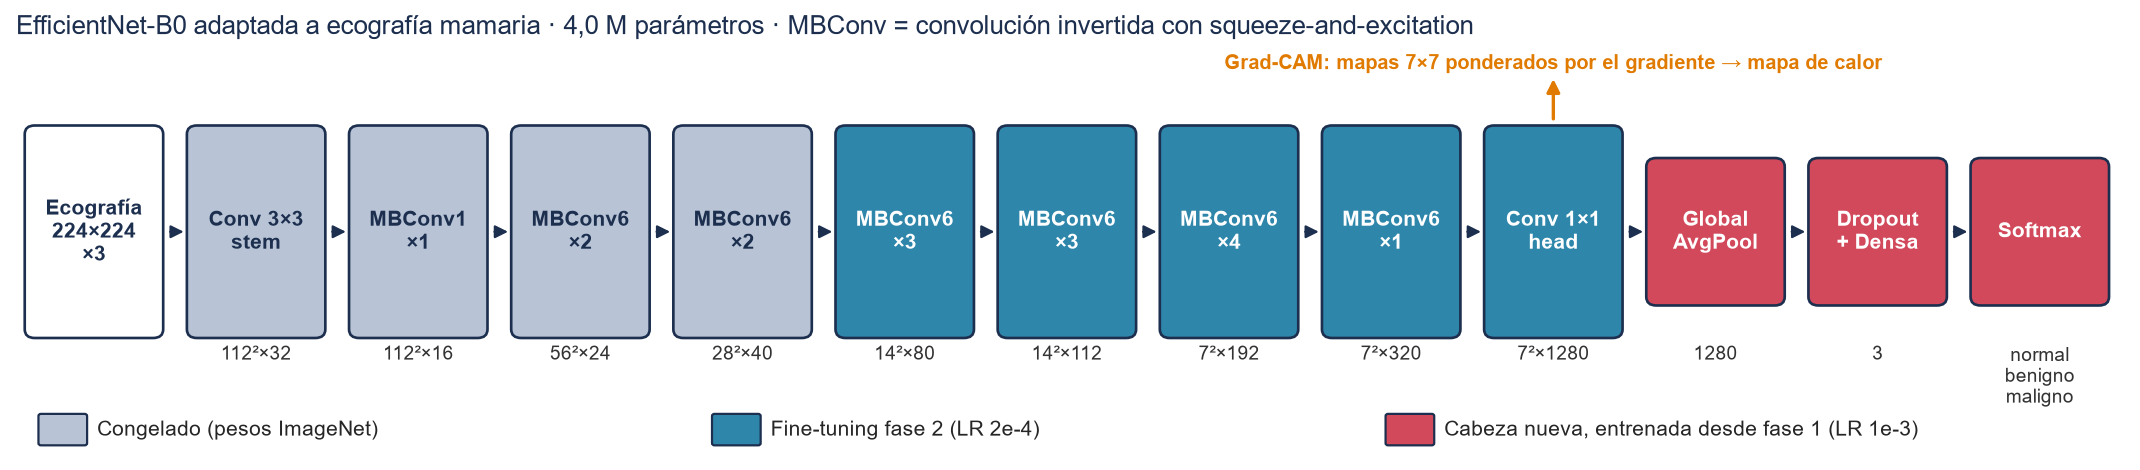

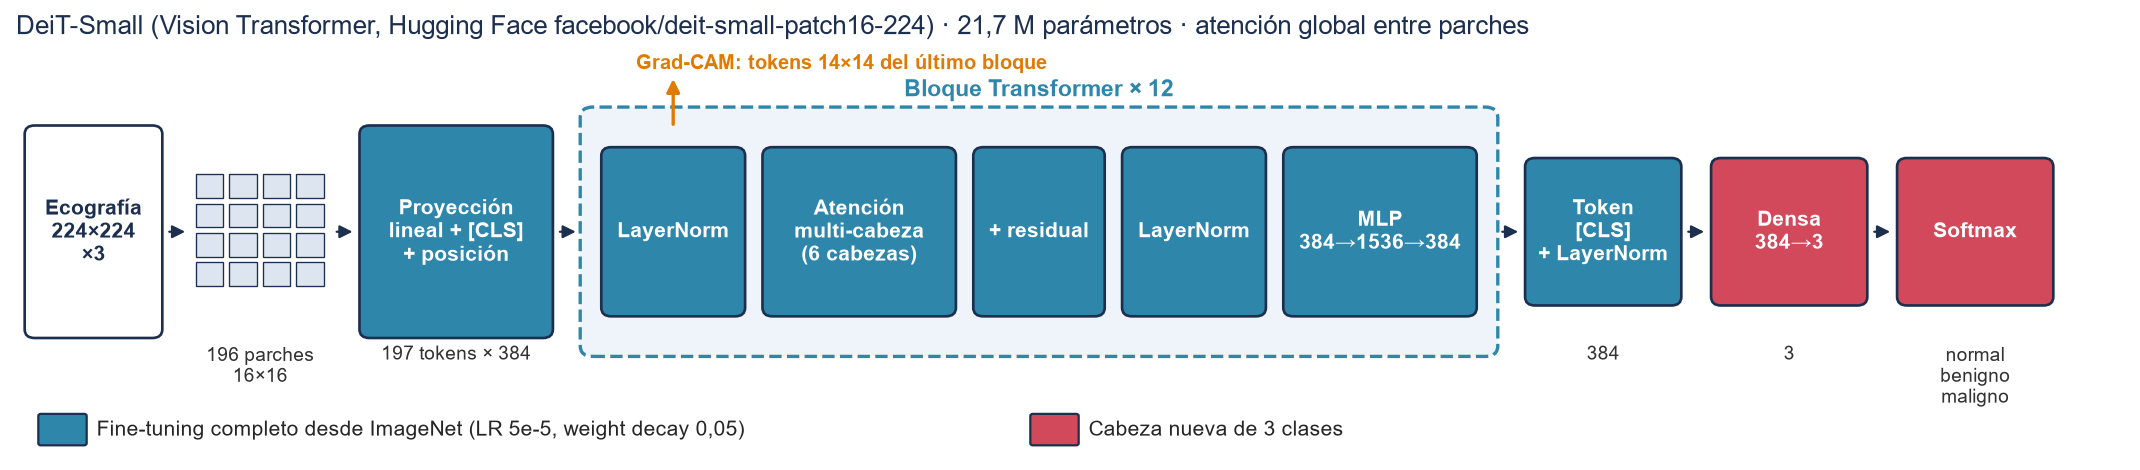

In [9]:
from utils.diagrama import dibujar_arquitectura, dibujar_vit
from IPython.display import Image as IPImage, display
display(IPImage(filename=str(dibujar_arquitectura())), IPImage(filename=str(dibujar_vit())))

### 5.1 CNN desde cero (línea base)

In [10]:
RESULTADOS, HISTORIALES = {}, {}
fijar_semillas(SEED)
cnn = CNNSimple()
print("Parámetros (total, entrenables):", contar_parametros(cnn))
t0 = time.time()
HISTORIALES["CNN desde cero"] = entrenar(cnn, dl_train, dl_val, epocas=30, lr=1e-3, pesos_clase=PESOS,
                                         paciencia=8, fase="cnn")
print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min")

Parámetros (total, entrenables): (1173987, 1173987)


[cnn] ép 01 | loss 1.150/1.536 | acc 0.396/0.278 | F1 val 0.145 | 88s


[cnn] ép 02 | loss 1.047/1.824 | acc 0.412/0.176 | F1 val 0.118 | 95s


[cnn] ép 03 | loss 0.994/1.155 | acc 0.479/0.361 | F1 val 0.380 | 94s


[cnn] ép 04 | loss 0.972/0.945 | acc 0.465/0.491 | F1 val 0.357 | 99s


[cnn] ép 05 | loss 0.972/0.988 | acc 0.499/0.602 | F1 val 0.607 | 121s


... (4 outputs left out)

[cnn] ép 10 | loss 0.779/0.896 | acc 0.582/0.565 | F1 val 0.563 | 106s


[cnn] ép 11 | loss 0.733/1.242 | acc 0.631/0.417 | F1 val 0.444 | 99s


[cnn] ép 12 | loss 0.744/0.873 | acc 0.607/0.481 | F1 val 0.431 | 93s


[cnn] ép 13 | loss 0.713/0.746 | acc 0.651/0.602 | F1 val 0.555 | 92s
  early stopping (mejor F1 val = 0.607)
Tiempo total: 21.4 min


### 5.2 EfficientNet-B0 con *transfer learning* en dos fases
1. **Fase 1 – extracción de características:** se congela toda la red preentrenada y sólo se entrena la nueva cabeza de 3 clases (LR = 1e-3). *Detalle técnico:* `timm` inicializa la cabeza con pesos U(±1/√3); con 1 280 entradas eso produce logits enormes (pérdida inicial ≈ 3,5) y la fase 1 no converge. Por eso la cabeza se reinicia con pesos N(0; 0,01) y sesgo 0 (`utils/modelos.py`).
2. **Fase 2 – ajuste fino (fine-tuning):** se descongelan los 4 últimos bloques + `conv_head` con una tasa 5 veces menor (LR = 2e-4) para adaptar los filtros de alto nivel a la textura del ultrasonido sin destruir lo aprendido.

In [11]:
fijar_semillas(SEED)
effnet = crear_efficientnet(preentrenado=True)
t0 = time.time()
congelar_efficientnet(effnet, bloques_entrenables=0)
print("Fase 1 – parámetros (total, entrenables):", contar_parametros(effnet))
h = entrenar(effnet, dl_train, dl_val, epocas=8, lr=1e-3, pesos_clase=PESOS, paciencia=4, fase="effnet-f1")
congelar_efficientnet(effnet, bloques_entrenables=4)
print("Fase 2 – parámetros (total, entrenables):", contar_parametros(effnet))
HISTORIALES["EfficientNet-B0"] = entrenar(effnet, dl_train, dl_val, epocas=20, lr=2e-4, pesos_clase=PESOS,
                                          paciencia=6, historial=h, fase="effnet-f2")
print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min")

Fase 1 – parámetros (total, entrenables): (4011391, 3843)


[effnet-f1] ép 01 | loss 1.050/1.031 | acc 0.454/0.472 | F1 val 0.433 | 28s


[effnet-f1] ép 02 | loss 0.949/0.937 | acc 0.609/0.630 | F1 val 0.557 | 28s


[effnet-f1] ép 03 | loss 0.892/0.923 | acc 0.576/0.657 | F1 val 0.592 | 30s


[effnet-f1] ép 04 | loss 0.817/0.859 | acc 0.677/0.704 | F1 val 0.631 | 30s


[effnet-f1] ép 05 | loss 0.795/0.875 | acc 0.661/0.630 | F1 val 0.600 | 30s


... (15 outputs left out)

[effnet-f2] ép 13 | loss 0.050/0.569 | acc 0.986/0.843 | F1 val 0.812 | 58s


[effnet-f2] ép 14 | loss 0.080/0.588 | acc 0.970/0.852 | F1 val 0.819 | 60s


[effnet-f2] ép 15 | loss 0.051/0.615 | acc 0.994/0.852 | F1 val 0.826 | 56s


[effnet-f2] ép 16 | loss 0.052/0.623 | acc 0.980/0.852 | F1 val 0.822 | 62s
  early stopping (mejor F1 val = 0.826)
Tiempo total: 18.5 min


### 5.3 Vision Transformer (DeiT-Small) de Hugging Face
Se descarga el modelo preentrenado con `transformers`, se reemplaza la cabeza de 1000 clases por una de 3 y se hace *fine-tuning* completo con una tasa baja (5e-5) y `weight_decay` = 0,05, configuración habitual para Transformers.

In [12]:
fijar_semillas(SEED)
vit = ViTClasificador(preentrenado=True)
print("Parámetros (total, entrenables):", contar_parametros(vit))
t0 = time.time()
HISTORIALES["DeiT-Small (ViT)"] = entrenar(vit, dl_train, dl_val, epocas=12, lr=5e-5, pesos_clase=PESOS, paciencia=4,
                                          weight_decay=0.05, fase="vit")
print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min")
MODELOS = {"CNN desde cero": cnn, "EfficientNet-B0": effnet, "DeiT-Small (ViT)": vit}
ARQ = {"CNN desde cero": ("cnn_simple", "cnn_simple_busi.pt"), "EfficientNet-B0": ("efficientnet_b0", "efficientnet_b0_busi.pt"),
       "DeiT-Small (ViT)": ("deit_small", "deit_small_busi.pt")}

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([3, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Parámetros (total, entrenables): (21666819, 21666819)


[vit] ép 01 | loss 0.939/0.694 | acc 0.521/0.741 | F1 val 0.734 | 141s


[vit] ép 02 | loss 0.537/0.605 | acc 0.751/0.722 | F1 val 0.715 | 145s


[vit] ép 03 | loss 0.427/0.541 | acc 0.842/0.815 | F1 val 0.805 | 159s


... (3 outputs left out)

[vit] ép 07 | loss 0.121/0.512 | acc 0.955/0.833 | F1 val 0.812 | 153s


[vit] ép 08 | loss 0.151/0.489 | acc 0.945/0.824 | F1 val 0.793 | 147s


[vit] ép 09 | loss 0.208/0.523 | acc 0.935/0.833 | F1 val 0.813 | 163s


[vit] ép 10 | loss 0.115/0.534 | acc 0.953/0.852 | F1 val 0.825 | 148s
  early stopping (mejor F1 val = 0.839)
Tiempo total: 25.8 min


## 6. PASO 4 – Evaluación y métricas

### 6.1 Curvas de entrenamiento y validación

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex="col")
for c, (nombre, hist) in enumerate(HISTORIALES.items()):
    h = pd.DataFrame(hist)
    axes[0, c].plot(h.epoca, h.loss_train, "o-", label="entrenamiento", ms=3)
    axes[0, c].plot(h.epoca, h.loss_val, "o-", label="validación", ms=3)
    axes[1, c].plot(h.epoca, h.acc_train, "o-", label="accuracy entren.", ms=3)
    axes[1, c].plot(h.epoca, h.acc_val, "o-", label="accuracy val.", ms=3)
    axes[1, c].plot(h.epoca, h.f1_val, "s--", label="F1 macro val.", ms=3)
    mejor = h.loc[h.f1_val.idxmax()]
    for a in axes[:, c]:
        a.axvline(mejor.epoca, color="gray", ls=":", lw=1)
    if (h.fase == "effnet-f2").any():
        for a in axes[:, c]:
            a.axvspan(h[h.fase == "effnet-f2"].epoca.min() - .5, h.epoca.max() + .5, color="orange", alpha=.08)
        axes[0, c].text(h[h.fase == "effnet-f2"].epoca.min(), axes[0, c].get_ylim()[1] * .95, " fine-tuning", color="darkorange")
    axes[0, c].set_title(nombre); axes[1, c].set_xlabel("Época")
axes[0, 0].set_ylabel("Pérdida (entropía cruzada)"); axes[1, 0].set_ylabel("Métrica")
axes[0, 0].legend(); axes[1, 0].legend(loc="lower right")
fig.suptitle("Curvas de aprendizaje (línea punteada = época con mejor F1 de validación)", fontsize=13)
guardar(fig, "05_curvas_entrenamiento.png")

### 6.2 Desempeño en el conjunto de prueba (imágenes nunca vistas)

In [14]:
PROBS = {}
filas = []
for nombre, m in MODELOS.items():
    y_test, p = predecir(m, dl_test)
    PROBS[nombre] = p
    r = metricas(y_test, p)
    r["ic95"] = bootstrap_ic(y_test, p)
    r["f1_macro_val"] = max(x["f1_val"] for x in HISTORIALES[nombre])
    r["parametros"] = contar_parametros(m)[0]
    r["epocas"] = len(HISTORIALES[nombre])
    r["min_entrenamiento"] = sum(x["seg"] for x in HISTORIALES[nombre]) / 60
    RESULTADOS[nombre] = r
    filas.append({"Modelo": nombre, "Parámetros (M)": r["parametros"] / 1e6, "Épocas": r["epocas"],
                  "Min. entrenamiento": r["min_entrenamiento"], "F1 macro (val)": r["f1_macro_val"],
                  "Accuracy": r["accuracy"], "F1 macro": r["f1_macro"], "ROC-AUC (OvR)": r["roc_auc_ovr"],
                  "Recall maligno": r["recall_maligno"]})
comp = pd.DataFrame(filas).set_index("Modelo")
display(comp.style.format("{:.3f}").format("{:.1f}", subset=["Parámetros (M)", "Min. entrenamiento"])
        .format("{:d}", subset=["Épocas"]).background_gradient(subset=["F1 macro", "Recall maligno"], cmap="Greens"))
for nombre, r in RESULTADOS.items():
    ic = r["ic95"]
    print(f"{nombre:18s} IC95% → accuracy {ic['accuracy'][0]:.3f}–{ic['accuracy'][1]:.3f} · "
          f"F1 macro {ic['f1_macro'][0]:.3f}–{ic['f1_macro'][1]:.3f} · recall maligno {ic['recall_maligno'][0]:.3f}–{ic['recall_maligno'][1]:.3f}")

,Parámetros (M),Épocas,Min. entrenamiento,F1 macro (val),Accuracy,F1 macro,ROC-AUC (OvR),Recall maligno
Modelo,,,,,,,,
CNN desde cero,1.2,13,21.4,0.607,0.569,0.554,0.746,0.581
EfficientNet-B0,4.0,24,18.5,0.826,0.872,0.844,0.975,0.806
DeiT-Small (ViT),21.7,10,25.8,0.839,0.927,0.924,0.979,0.903


CNN desde cero     IC95% → accuracy 0.477–0.661 · F1 macro 0.454–0.651 · recall maligno 0.407–0.750
EfficientNet-B0    IC95% → accuracy 0.807–0.927 · F1 macro 0.756–0.920 · recall maligno 0.667–0.931
DeiT-Small (ViT)   IC95% → accuracy 0.872–0.972 · F1 macro 0.869–0.971 · recall maligno 0.793–1.000


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (nombre, r) in zip(axes, RESULTADOS.items()):
    cm = np.array(r["matriz_confusion"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=CLASES, yticklabels=CLASES,
                annot_kws={"size": 14})
    a.set_title(f"{nombre}\naccuracy {r['accuracy']:.3f} · F1 macro {r['f1_macro']:.3f}"); a.set_xlabel("Predicho"); a.set_ylabel("Real")
fig.suptitle(f"Matrices de confusión en prueba (n = {len(df_test)})", fontsize=13)
guardar(fig, "06_matrices_confusion.png")

In [16]:
from sklearn.metrics import roc_curve, auc
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (nombre, p) in zip(axes, PROBS.items()):
    for k, clase in enumerate(CLASES):
        fpr, tpr, _ = roc_curve(y_test == k, p[:, k])
        a.plot(fpr, tpr, color=COLORES[clase], lw=2, label=f"{clase} (AUC {auc(fpr, tpr):.3f})")
    a.plot([0, 1], [0, 1], "k--", lw=.8); a.set_title(nombre); a.set_xlabel("1 − especificidad"); a.legend(loc="lower right")
axes[0].set_ylabel("Sensibilidad")
fig.suptitle("Curvas ROC uno-contra-resto en prueba", fontsize=13)
guardar(fig, "07_roc.png")

# Comparación visual de modelos
fig, ax = plt.subplots(figsize=(10, 4))
comp[["Accuracy", "F1 macro", "ROC-AUC (OvR)", "Recall maligno"]].plot.bar(ax=ax, rot=0, width=.8, colormap="viridis")
ax.set_ylim(0, 1.05); ax.set_ylabel("Valor en prueba"); ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(.5, 1.0))
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
guardar(fig, "08_comparacion_modelos.png")

In [17]:
from sklearn.metrics import classification_report
MEJOR = comp["F1 macro (val)"].idxmax()     # selección por VALIDACIÓN, no por prueba
print(f"Modelo con mejor F1 macro en validación: {MEJOR}\n")
print(classification_report(y_test, PROBS[MEJOR].argmax(1), target_names=CLASES, digits=3))

Modelo con mejor F1 macro en validación: DeiT-Small (ViT)

              precision    recall  f1-score   support

      normal      0.857     1.000     0.923        18
     benigno      0.948     0.917     0.932        60
     maligno      0.933     0.903     0.918        31

    accuracy                          0.927       109
   macro avg      0.913     0.940     0.924       109
weighted avg      0.929     0.927     0.927       109



### 6.3 Interpretabilidad con Grad-CAM
Grad-CAM pondera los mapas de activación de la última capa convolucional (en el ViT, los 14×14 tokens de parche del último bloque) por el gradiente de la clase predicha; el resultado es un mapa de calor de las zonas que **más empujaron** la decisión. Como BUSI trae la **máscara de la lesión**, podemos medirlo: qué fracción de la "energía" del mapa cae dentro de la lesión. Si la red mirara al azar, esa fracción sería igual al área de la lesión.

In [18]:
def energia_gradcam(modelo):
    # Fracción de la energía Grad-CAM dentro de la lesión (clase real) en las imágenes de prueba con máscara
    gc_ = GradCAM(modelo, capa_objetivo(modelo))
    energias, areas = [], []
    for i, arch in enumerate(df_test.archivo):
        ruta = DIR_RAW / arch
        mascaras = list(ruta.parent.glob(f"{ruta.stem}_mask*.png"))
        if df_test.clase.iloc[i] == "normal" or not mascaras:
            continue
        cam, _ = gc_(ds_test[i][0].unsqueeze(0), clase=CLASES.index(df_test.clase.iloc[i]))
        mk = np.zeros(Image.open(mascaras[0]).size[::-1], bool)
        for m in mascaras:
            mk |= np.asarray(Image.open(m).convert("L")) > 127
        energias.append(energia_en_mascara(cam, mk)); areas.append(mk.mean())
    e, a = np.array(energias), np.array(areas)
    return {"energia_media_en_lesion": float(e.mean()), "area_media_lesion": float(a.mean()),
            "razon": float(e.mean() / a.mean()), "n": int(len(e))}

GRADCAM_MODELOS = {n: energia_gradcam(MODELOS[n]) for n in ("EfficientNet-B0", "DeiT-Small (ViT)")}
for n, g_ in GRADCAM_MODELOS.items():
    print(f"{n:18s} · {g_['n']} lesiones de prueba: {g_['energia_media_en_lesion']:.1%} de la energía Grad-CAM cae dentro "
          f"de la lesión (área media {g_['area_media_lesion']:.1%}) → {g_['razon']:.1f}× lo esperado al azar.")

# Galería del modelo seleccionado: aciertos y errores
cam_m = GradCAM(MODELOS[MEJOR], capa_objetivo(MODELOS[MEJOR]))
pred_m = PROBS[MEJOR].argmax(1)
sel = []
for k in range(len(CLASES)):
    sel += list(np.where((y_test == k) & (pred_m == k))[0][:2])
errores = np.where(y_test != pred_m)[0]
sel += list(errores[:3])
fig, axes = plt.subplots(2, len(sel), figsize=(2.3 * len(sel), 5))
for c, i in enumerate(sel):
    img = Image.open(DIR_RAW / df_test.archivo.iloc[i]).convert("RGB")
    cam, pr = cam_m(ds_test[i][0].unsqueeze(0))
    axes[0, c].imshow(img); axes[1, c].imshow(superponer(img, cam))
    ok_ = y_test[i] == pred_m[i]
    axes[0, c].set_title(f"real: {CLASES[y_test[i]]}", fontsize=9)
    axes[1, c].set_title(f"pred: {CLASES[pred_m[i]]} {pr.max():.0%}", fontsize=9, color="green" if ok_ else "red")
    for a in axes[:, c]:
        a.axis("off")
fig.suptitle(f"Grad-CAM de {MEJOR} en prueba (verde = acierto, rojo = error)", fontsize=12)
guardar(fig, "09_gradcam.png")

EfficientNet-B0    · 91 lesiones de prueba: 23.5% de la energía Grad-CAM cae dentro de la lesión (área media 8.5%) → 2.8× lo esperado al azar.
DeiT-Small (ViT)   · 91 lesiones de prueba: 15.5% de la energía Grad-CAM cae dentro de la lesión (área media 8.5%) → 1.8× lo esperado al azar.


In [19]:
# Análisis de errores del modelo seleccionado
err = df_test.iloc[errores][["archivo", "clase", "area_lesion"]].copy()
err["predicho"] = [CLASES[k] for k in pred_m[errores]]
err["confianza"] = PROBS[MEJOR][errores].max(1).round(3)
print(f"{MEJOR}: {len(err)} errores de {len(df_test)}")
display(err.sort_values("confianza", ascending=False))

DeiT-Small (ViT): 8 errores de 109


,archivo,clase,area_lesion,predicho,confianza
52,benign/benign (334).png,benigno,0.024084,maligno,0.978
49,benign/benign (32).png,benigno,0.120354,normal,0.972
85,malignant/malignant (167).png,maligno,0.222845,benigno,0.970
53,benign/benign (335).png,benigno,0.067939,normal,0.923
98,malignant/malignant (48).png,maligno,0.046403,benigno,0.875
65,benign/benign (391).png,benigno,0.135930,normal,0.846
93,malignant/malignant (204).png,maligno,0.092495,benigno,0.834
34,benign/benign (233).png,benigno,0.164458,maligno,0.483


## 7. Puente con el ACA 1: MLP vs. regresión logística en WDBC
Para cerrar el ciclo, entrenamos un **perceptrón multicapa (MLP)** en PyTorch sobre las 30 variables del ACA 1 (misma partición 80/20, semilla 42) y lo comparamos con la regresión logística ganadora del ACA 1.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score as f1s, roc_auc_score, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn

wdbc = pd.read_csv(BASE / "data" / "wdbc_limpio.csv")
Xw, yw = wdbc.drop(columns="diagnosis").values, wdbc["diagnosis"].values
Xtr, Xte, ytr, yte = train_test_split(Xw, yw, test_size=.20, stratify=yw, random_state=SEED)
Xtr2, Xva2, ytr2, yva2 = train_test_split(Xtr, ytr, test_size=.20, stratify=ytr, random_state=SEED)
sc = StandardScaler().fit(Xtr2)
T = lambda a: torch.tensor(sc.transform(a), dtype=torch.float32)

fijar_semillas(SEED)
mlp = nn.Sequential(nn.Linear(30, 64), nn.ReLU(), nn.Dropout(.2), nn.Linear(64, 32), nn.ReLU(), nn.Dropout(.2), nn.Linear(32, 1))
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
bce = nn.BCEWithLogitsLoss()
hist_mlp, mejor, estado, paciencia = [], 1e9, None, 0
for ep in range(300):
    mlp.train(); opt.zero_grad(); l = bce(mlp(T(Xtr2)).squeeze(1), torch.tensor(ytr2, dtype=torch.float32)); l.backward(); opt.step()
    mlp.eval()
    with torch.no_grad():
        lv = bce(mlp(T(Xva2)).squeeze(1), torch.tensor(yva2, dtype=torch.float32)).item()
    hist_mlp.append((l.item(), lv))
    if lv < mejor - 1e-4:
        mejor, estado, paciencia = lv, {k: v.clone() for k, v in mlp.state_dict().items()}, 0
    else:
        paciencia += 1
        if paciencia >= 25:
            break
mlp.load_state_dict(estado); mlp.eval()
with torch.no_grad():
    p_mlp = torch.sigmoid(mlp(T(Xte))).squeeze(1).numpy()
lr_ = LogisticRegression(C=1, max_iter=5000).fit(sc.transform(Xtr2), ytr2)
p_lr = lr_.predict_proba(sc.transform(Xte))[:, 1]
PUENTE = {}
for nombre, p in [("Regresión logística (ACA 1)", p_lr), ("MLP 30-64-32-1 (ACA 2)", p_mlp)]:
    PUENTE[nombre] = {"accuracy": accuracy_score(yte, p >= .5), "f1": f1s(yte, p >= .5), "roc_auc": roc_auc_score(yte, p)}
display(pd.DataFrame(PUENTE).T.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
hm = np.array(hist_mlp)
axes[0].plot(hm[:, 0], label="entrenamiento"); axes[0].plot(hm[:, 1], label="validación")
axes[0].set_title("MLP en WDBC: curva de pérdida"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("BCE"); axes[0].legend()
pd.DataFrame(PUENTE).T.plot.bar(ax=axes[1], rot=0, colormap="coolwarm"); axes[1].set_ylim(.85, 1.01)
axes[1].set_title("WDBC – prueba (n = 114)"); axes[1].legend(loc="lower right")
guardar(fig, "10_puente_wdbc.png")

,accuracy,f1,roc_auc
Regresión logística (ACA 1),0.982,0.976,0.996
MLP 30-64-32-1 (ACA 2),0.991,0.988,0.998


**Lectura.** En WDBC ambos modelos quedan prácticamente empatados (la diferencia es de uno o dos casos en 114, dentro del margen de error de una muestra tan pequeña). Con 30 variables tabulares ya construidas por expertos el problema es casi linealmente separable, así que una red neuronal aporta poco frente a un modelo lineal más simple e interpretable. El valor del Deep Learning aparece cuando la entrada es la **imagen cruda**, donde no existen esas variables pre-calculadas: eso es lo que resuelven las redes de este proyecto.

## 8. Exportación de artefactos para la app (PASO 5)
La app usa el modelo con **mejor F1 macro en validación** (la prueba no interviene en la elección). Se guardan los pesos de las tres redes (y la configuración del ViT, para que la app no descargue nada), las métricas, el historial y nueve imágenes de **prueba** como ejemplos.

In [21]:
for nombre, m in MODELOS.items():
    torch.save(m.state_dict(), DIR_MODELOS / ARQ[nombre][1])
vit.vit.config.save_pretrained(DIR_MODELOS / "deit_small_config")
print("Modelo para la app (mejor F1 macro en validación):", MEJOR)
print("Pesos guardados:", [f"{p.name} ({p.stat().st_size / 1e6:.1f} MB)" for p in DIR_MODELOS.glob("*.pt")])

def limpio(o):
    if isinstance(o, dict):
        return {k: limpio(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [limpio(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return round(float(o), 4)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o

conteo = db.consultar(con, "SELECT particion, COUNT(*) n FROM imagenes WHERE excluida=0 GROUP BY particion").set_index("particion").n
metr = {
    "modelo_app": MEJOR, "arquitectura_app": ARQ[MEJOR][0], "pesos_app": ARQ[MEJOR][1],
    "clases": CLASES, "img_size": IMG_SIZE, "modelo_mejor_val": MEJOR,
    "n": {"total_original": len(inv), "excluidas": int(dep.excluida.sum()), **{k: int(v) for k, v in conteo.items()}},
    "depuracion": dep.motivo.value_counts().to_dict(),
    "resultados_test": RESULTADOS, "gradcam": GRADCAM_MODELOS.get(MEJOR, {}), "gradcam_por_modelo": GRADCAM_MODELOS,
    "puente_wdbc": PUENTE,
    "historial": HISTORIALES,
}
(DIR_MODELOS / "metricas.json").write_text(json.dumps(limpio(metr), ensure_ascii=False, indent=2), encoding="utf-8")

# Ejemplos para la app: 3 imágenes de PRUEBA por clase
for f in DIR_EJEMPLOS.glob("*.png"):
    f.unlink()
for clase in CLASES:
    for k, arch in enumerate(df_test[df_test.clase == clase].archivo.iloc[[0, 5, 10]]):
        shutil.copy(DIR_RAW / arch, DIR_EJEMPLOS / f"{clase}_{k + 1}.png")
print("Ejemplos:", sorted(p.name for p in DIR_EJEMPLOS.glob("*.png")))
con.close()

Modelo para la app (mejor F1 macro en validación): DeiT-Small (ViT)
Pesos guardados: ['cnn_simple_busi.pt (4.7 MB)', 'deit_small_busi.pt (86.7 MB)', 'efficientnet_b0_busi.pt (16.3 MB)']
Ejemplos: ['benigno_1.png', 'benigno_2.png', 'benigno_3.png', 'maligno_1.png', 'maligno_2.png', 'maligno_3.png', 'normal_1.png', 'normal_2.png', 'normal_3.png']


## 9. Conclusiones, limitaciones y referencias

### Respuesta a la pregunta orientadora
Las arquitecturas de redes neuronales **sí permiten extraer patrones complejos directamente de la imagen médica**, sin variables calculadas a mano, siempre que se combinen con *transfer learning* y con un manejo cuidadoso de los datos. El Vision Transformer **DeiT-Small** de Hugging Face, ajustado sobre ~500 ecografías, clasifica tejido normal, lesiones benignas y malignas con **accuracy 92,7 %, F1 macro 0,924 y ROC-AUC 0,979** en 109 imágenes nunca vistas, y se usa de forma práctica en la app Streamlit con explicación visual Grad-CAM e historial en SQLite.

### Conclusiones
1. **Transfer learning vs. entrenar desde cero.** Con tan pocos datos, la CNN desde cero se queda muy por debajo (F1 macro 0,554, ROC-AUC 0,746) y sus curvas de validación oscilan mucho. Las redes preentrenadas en ImageNet llegan a F1 0,844 (EfficientNet-B0) y 0,924 (DeiT-Small): reutilizar filtros y representaciones aprendidas en millones de imágenes es lo que hace viable el Deep Learning con datasets médicos pequeños.
2. **Transformer vs. CNN.** El ViT superó a EfficientNet-B0 en validación (F1 0,840 vs. 0,826) y en prueba (0,924 vs. 0,844). La autoatención relaciona todos los parches de la imagen, lo que ayuda a valorar la forma de la lesión junto con su entorno (bordes, sombra acústica). A cambio, es 5 veces más grande (21,7 M vs. 4,0 M parámetros) y más lento en CPU.
3. **Sensibilidad para la clase maligna.** El modelo de la app detecta 28 de 31 tumores malignos (recall 90,3 %, IC 95 % 0,79–1,00) y ninguna imagen normal se clasifica como maligna. Los 3 malignos no detectados se confunden con benignos; por eso la app agrega un **umbral de revisión** que alerta cuando P(maligno) supera 0,30 aunque la clase más probable sea otra.
4. **Calidad de datos.** La depuración con hash perceptual encontró 18 imágenes con la misma ecografía en dos clases y 38 duplicados. Excluirlas y agrupar las casi idénticas en la partición evita la fuga de información: las métricas reportadas son honestas.
5. **Un error de implementación con impacto real.** La inicialización por defecto de la cabeza en `timm` hacía que la fase 1 de EfficientNet no convergiera (pérdida ≈ 3,5). Corregirla subió su accuracy en prueba de 81,7 % a 87,2 %: revisar las curvas de pérdida desde la primera época es parte del análisis, no un detalle.
6. **Interpretabilidad.** Grad-CAM concentra dentro de la lesión 2,8× (EfficientNet) y 1,8× (ViT) más energía de la esperada al azar. Ambos modelos miran la anatomía relevante; la CNN de forma más localizada y el Transformer de forma más global.
7. **Puente con el ACA 1.** Con las 30 variables tabulares de WDBC, la MLP y la regresión logística empatan (F1 0,988 vs. 0,976, una diferencia de un caso en 114). El valor diferencial del Deep Learning está en aprender de datos no estructurados como la imagen.

### Limitaciones
- Un único hospital y equipo de ultrasonido; sin validación externa.
- Conjunto de prueba pequeño (109 imágenes): los intervalos de confianza son amplios.
- BUSI tiene etiquetas inconsistentes conocidas; algunas imágenes incluyen texto o marcas del ecógrafo.
- Entrenamiento en CPU con una sola semilla; no se exploraron más hiperparámetros ni validación cruzada por el costo computacional.
- Herramienta **educativa**: no es un dispositivo médico ni sustituye el diagnóstico profesional.

### Referencias (APA 7)
- Al-Dhabyani, W., Gomaa, M., Khaled, H., & Fahmy, A. (2020). Dataset of breast ultrasound images. *Data in Brief, 28*, 104863. https://doi.org/10.1016/j.dib.2019.104863
- Dosovitskiy, A., Beyer, L., Kolesnikov, A., Weissenborn, D., Zhai, X., Unterthiner, T., ... & Houlsby, N. (2021). An image is worth 16x16 words: Transformers for image recognition at scale. *International Conference on Learning Representations*.
- Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. *Proceedings of the IEEE International Conference on Computer Vision*, 618–626.
- Tan, M., & Le, Q. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *Proceedings of the 36th International Conference on Machine Learning*, 6105–6114.
- Touvron, H., Cord, M., Douze, M., Massa, F., Sablayrolles, A., & Jégou, H. (2021). Training data-efficient image transformers & distillation through attention. *Proceedings of the 38th International Conference on Machine Learning*, 10347–10357.
- Wolberg, W., Street, N., & Mangasarian, O. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., ... & Rush, A. M. (2020). Transformers: State-of-the-art natural language processing. *Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations*, 38–45.